# Atendimento sob evidência: a dor existe?

Antes de construir um sistema de gestão de chamados, este notebook verifica com dados públicos se o problema que ele resolve é real.

**Pergunta:** entre as reclamações finalizadas no Consumidor.gov.br em 2025 e avaliadas pelo consumidor, respostas acima de 7 dias estão associadas a mais casos **não resolvidos**, comparando dentro da mesma empresa e do mesmo tipo de problema?

| | Hipótese |
|---|---|
| **H₀** | Dentro de cada estrato empresa × grupo de problema, o rótulo resolvida/não resolvida não depende da faixa de tempo (os rótulos são permutáveis). |
| **H₁** | A diferença ponderada de não resolução é **positiva** para respostas acima de 7 dias (teste unilateral, α = 5%). |

O corte de 7 dias, a direção do teste e o α foram fixados no [plano de análise](../docs/plano_analise.md) antes dos resultados.

**Como o código está organizado:** cada etapa abaixo chama uma função do pacote [`atendimento/`](../atendimento/). Assim, a lógica tem testes automatizados (`tests/`) e o notebook fica dedicado à narrativa. Os dados são os arquivos oficiais, baixados com `python -m atendimento baixar`.

In [1]:
import sys
from pathlib import Path
import inspect, json

import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from atendimento import config, data, describe, pipeline, plots, stats

if len(list(config.RAW_DIR.glob('finalizadas_2025-*.zip'))) != 12:
    raise FileNotFoundError('Dados brutos ausentes. Na pasta analise/, rode: python -m atendimento baixar')

plots.setup_style()
say = lambda text: print(text.translate(str.maketrans({',': '.', '.': ','})))  # números em pt-BR
fmt = dict(decimal=',', thousands='.')

## 1. Os dados

São 12 arquivos mensais oficiais, verificados pelo SHA-256 registrado em `data/manifest.json`. A leitura valida o esquema, as categorias, as datas e se o mês do arquivo bate com a data de finalização. Só as colunas necessárias são lidas, sem dados pessoais.

In [2]:
manifest = data.load_manifest()
df = data.load_data(manifest)
say(f"{len(df):,} reclamações · {df['company'].nunique():,} empresas · {df['segment'].nunique()} segmentos · {df['month'].nunique()} meses")
df.head()

2.328.863 reclamações · 1.740 empresas · 45 segmentos · 12 meses


,date,days,company,segment,problem_group,contacted,answered,evaluation,rating,source_month,month
0,2025-01-20,10.0,Banco Master (antigo Banco Máxima),"Bancos, Financeiras e Administradoras de Cartão",Cobrança / Contestação,S,S,Não Resolvida,1.0,2025-01,2025-01
1,2025-01-15,10.0,Cartões Itaú,"Bancos, Financeiras e Administradoras de Cartão",Contrato / Oferta,N,S,Não Resolvida,1.0,2025-01,2025-01
2,2025-01-12,10.0,BaneseCard,"Bancos, Financeiras e Administradoras de Cartão",Cobrança / Contestação,S,S,Não Resolvida,5.0,2025-01,2025-01
3,2025-01-27,7.0,BrasilCard,"Bancos, Financeiras e Administradoras de Cartão",Atendimento / SAC,S,S,Resolvida,5.0,2025-01,2025-01
4,2025-01-17,10.0,Banco Bradesco,"Bancos, Financeiras e Administradoras de Cartão",Cobrança / Contestação,N,S,Não Resolvida,3.0,2025-01,2025-01


A **amostra analítica** reúne as reclamações respondidas, avaliadas explicitamente (Resolvida ou Não Resolvida), com tempo válido e com empresa e grupo de problema preenchidos. As não avaliadas **não** contam como resolvidas.

In [3]:
analytic = data.analytic_sample(df)
quality = describe.quality(df, analytic)

funil = pd.DataFrame({
    'etapa': ['Finalizadas', 'Respondidas', 'Avaliadas explicitamente', 'Declaradas não resolvidas', 'Amostra analítica'],
    'reclamações': [quality['total_rows'], quality['answered_rows'], quality['evaluated_rows'],
                    quality['unresolved_evaluated_rows'], quality['analytic_rows']]})
funil['% das finalizadas'] = funil['reclamações'] / quality['total_rows'] * 100
funil.style.format({'reclamações': '{:,.0f}', '% das finalizadas': '{:.1f}%'}, **fmt).hide(axis='index')

etapa,reclamações,% das finalizadas
Finalizadas,2.328.863,"100,0%"
Respondidas,2.257.501,"96,9%"
Avaliadas explicitamente,769.636,"33,0%"
Declaradas não resolvidas,432.572,"18,6%"
Amostra analítica,748.771,"32,2%"


## 2. A dor existe e é grande

432 mil reclamações foram declaradas não resolvidas pelo próprio consumidor. Isso é 56% das avaliadas, e só um terço dos casos chega a ser avaliado.

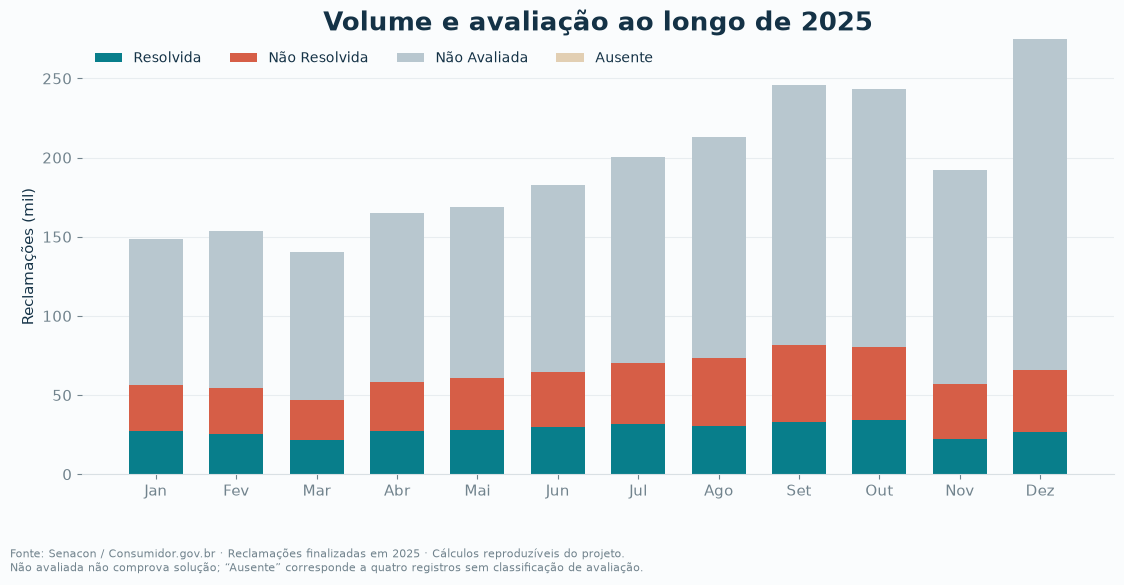

In [4]:
monthly = describe.monthly_counts(df)
plots.volume_mensal(monthly);

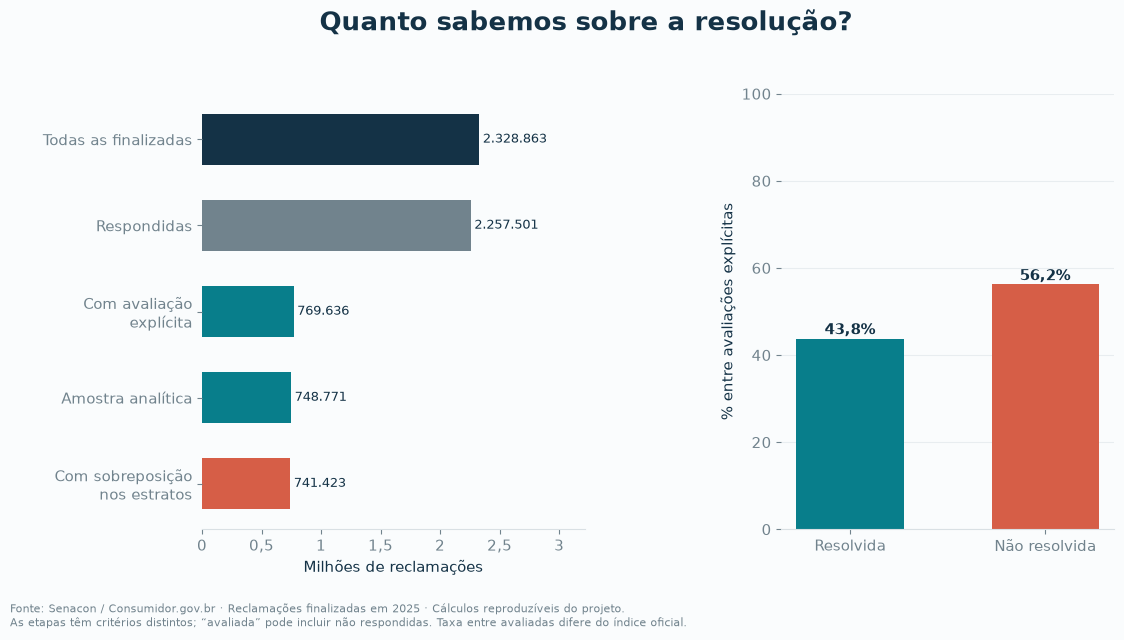

In [5]:
tab, coverage = stats.make_strata(analytic)  # detalhado na seção 4; aqui só a cobertura
plots.cobertura_e_resolucao(quality, coverage['included_rows']);

## 3. Tempo de resposta e desfecho (descritivo)

Antes do teste, as taxas brutas por faixa de tempo. A relação **não é linear**: respostas muito rápidas (0–2 dias) também têm alta não resolução, o que é compatível com respostas padronizadas que encerram o caso sem resolvê-lo. Por isso, "responder" e "resolver" precisam ser métricas separadas no sistema.

In [6]:
bands = describe.response_bands(analytic)
bands.assign(rate=bands['rate'] * 100, ci_lower=bands['ci_lower'] * 100, ci_upper=bands['ci_upper'] * 100) \
     .rename(columns={'size': 'avaliadas', 'sum': 'não resolvidas', 'rate': '% não resolvida', 'ci_lower': 'IC95% inf.', 'ci_upper': 'IC95% sup.'}) \
     .rename_axis('faixa (dias)') \
     .style.format({'avaliadas': '{:,.0f}', 'não resolvidas': '{:,.0f}', '% não resolvida': '{:.1f}', 'IC95% inf.': '{:.1f}', 'IC95% sup.': '{:.1f}'}, **fmt)

,avaliadas,não resolvidas,% não resolvida,IC95% inf.,IC95% sup.
faixa (dias),,,,,
0–2,151.856,89.424,"58,9","58,6","59,1"
3–5,132.681,71.753,"54,1","53,8","54,3"
6–7,136.739,70.375,"51,5","51,2","51,7"
8–10,310.395,173.982,"56,1","55,9","56,2"
>10,17.100,10.382,"60,7","60,0","61,4"


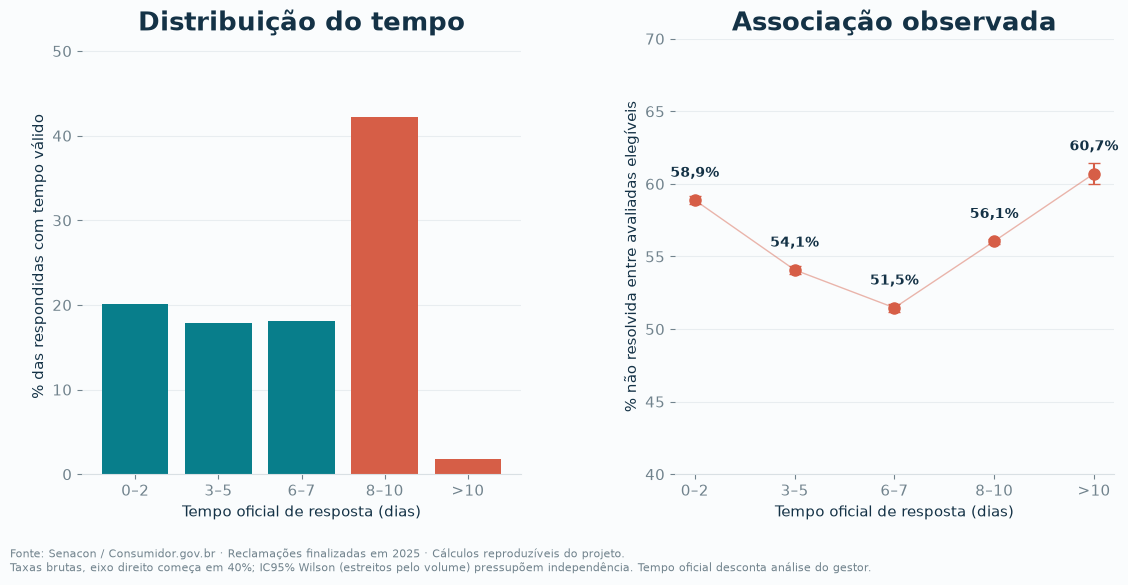

In [7]:
plots.tempo_e_desfecho(describe.time_distribution(df), bands);

Comparando só "até 7 dias" com "acima de 7 dias", a diferença bruta é pequena. Mas ela mistura empresas e problemas muito diferentes: um banco com muitas reclamações lentas pesa mais num lado do que no outro. O teste precisa comparar casos comparáveis.

In [8]:
crude = analytic.groupby(analytic['days'].gt(config.THRESHOLD_DAYS))['unresolved'].mean()
say(f"Bruto: até 7 dias = {crude[False]:.2%} · acima de 7 dias = {crude[True]:.2%} · diferença = {(crude[True] - crude[False]) * 100:+.2f} pp")

Bruto: até 7 dias = 54,96% · acima de 7 dias = 56,30% · diferença = +1,33 pp


## 4. Estratos: comparar dentro da mesma empresa e problema

Para cada combinação empresa × grupo de problema, conta-se quantos casos foram rápidos (`n0`) e lentos (`n1`), e quantos de cada grupo ficaram sem solução (`y0`, `y1`). Só entram os estratos que têm as duas faixas, porque nos outros não há comparação possível.

A estatística de teste é a média das diferenças dentro dos estratos, ponderada pelo tamanho de cada um:

$$T = \sum_s \frac{n_s}{N}\,\left(p^{\text{lenta}}_s - p^{\text{rápida}}_s\right)$$

In [9]:
observed = stats.weighted_effect(tab)

say(f"{coverage['eligible_strata']:,} estratos comparáveis de {coverage['all_strata']:,} · "
    f"{coverage['included_rows']:,} reclamações ({coverage['coverage_fraction']:.1%} da amostra analítica)")
say(f"T observado = {observed * 100:+.2f} pp")
tab.sort_values('n', ascending=False).head(8)[['company', 'problem_group', 'n0', 'y0', 'n1', 'y1', 'delta']] \
   .style.format({'delta': '{:+.3f}'}, **fmt).hide(axis='index')

4.121 estratos comparáveis de 6.542 · 741.423 reclamações (99,0% da amostra analítica)
T observado = +4,83 pp


company,problem_group,n0,y0,n1,y1,delta
Nubank,Cobrança / Contestação,24.722,21.408,1.743,1.232,"-0,159"
Serasa Experian,Dados Pessoais e Privacidade,16.797,10.580,4.052,2.808,"+0,063"
Vivo - Telefônica,Cobrança / Contestação,6.178,981,9.482,2.061,"+0,059"
Banco do Brasil,Cobrança / Contestação,12.654,9.117,1.575,1.106,"-0,018"
Banco Santander,Cobrança / Contestação,8.611,6.766,5.057,3.671,"-0,060"
Banco Bradesco,Cobrança / Contestação,2.196,1.599,8.733,6.995,"+0,073"
Serasa Experian,Cobrança / Contestação,8.403,5.216,2.395,1.658,"+0,072"
Banco Itaú Unibanco,Cobrança / Contestação,4.942,3.756,5.177,3.986,"+0,010"


## 5. Teste de permutação

**Ideia:** se H₀ for verdadeira, o tempo de resposta não tem relação com o desfecho dentro de cada estrato. Então, embaralhar os rótulos "resolvida/não resolvida" entre os casos de um estrato não deveria mudar nada de sistemático. Repetindo o embaralhamento milhares de vezes, obtemos a distribuição de T sob H₀ e vemos onde o valor observado cai nela.

Como o desfecho é binário, embaralhar os rótulos de um estrato equivale a sortear quantos não resolvidos vão para o grupo lento, a partir de uma distribuição **hipergeométrica**. É o mesmo teste, só que vetorizado: 9.999 permutações em 4 mil estratos levam segundos. O teste `test_statistics.py` confere esse algoritmo contra a enumeração de todas as permutações possíveis numa amostra pequena.

In [10]:
display(Markdown(f"```python\n{inspect.getsource(stats.permutation_distribution)}\n{inspect.getsource(stats.p_value)}```"))

```python
def permutation_distribution(tab: pd.DataFrame, permutations: int = PERMUTATIONS, seed: int = SEED) -> np.ndarray:
    """Hypergeometric counts are exactly label permutations conditional on margins.

    For each stratum, A = unresolved labels assigned to slow records follows
    Hypergeom(total unresolved, total resolved, number slow). Margins/weights
    remain fixed. Vectorized batches bound memory, with no normal approximation.
    """
    rng = np.random.default_rng(seed)
    n = tab['n'].to_numpy(dtype=np.int64)
    n1, n0 = tab['n1'].to_numpy(dtype=np.int64), tab['n0'].to_numpy(dtype=np.int64)
    total_y = (tab['y0'] + tab['y1']).to_numpy(dtype=np.int64)
    weights = n / n.sum()
    null = np.empty(permutations)
    for start in range(0, permutations, 128):
        size = min(128, permutations - start)
        a = rng.hypergeometric(total_y, n - total_y, n1, size=(size, len(tab)))
        delta = a / n1 - (total_y - a) / n0
        null[start:start + size] = delta @ weights
    return null

def p_value(null: np.ndarray, observed: float) -> tuple[float, int]:
    """One-sided Monte Carlo p-value with the (b + 1) / (B + 1) correction."""
    extremes = int((null >= observed - 1e-14).sum())
    return (extremes + 1) / (len(null) + 1), extremes
```

In [11]:
null = stats.permutation_distribution(tab, permutations=config.PERMUTATIONS, seed=config.SEED)
p, extremes = stats.p_value(null, observed)

say(f"Distribuição sob H₀: média {null.mean() * 100:+.3f} pp · desvio {null.std(ddof=1) * 100:.3f} pp · "
    f"de {null.min() * 100:+.3f} a {null.max() * 100:+.3f} pp")
say(f"Observado: {observed * 100:+.2f} pp · {observed / null.std(ddof=1):.0f} desvios-padrão acima do centro da distribuição sob H₀")
say(f"Permutações ≥ observado: {extremes} de {len(null):,}  →  p = (b + 1) / (B + 1) = {p:.4f}")

Distribuição sob H₀: média -0,001 pp · desvio 0,140 pp · de -0,476 a +0,615 pp
Observado: +4,83 pp · 35 desvios-padrão acima do centro da distribuição sob H₀
Permutações ≥ observado: 0 de 9.999  →  p = (b + 1) / (B + 1) = 0,0001


**Magnitude e incerteza.** O p-valor diz se o efeito é distinguível do acaso, mas não diz o tamanho dele. O intervalo de confiança reamostra **empresas inteiras** (4.999 vezes), porque reclamações da mesma empresa não são independentes entre si.

Efeito estratificado: +4,83 pp · IC95% por 1.054 empresas: 2,43 a 6,99 pp
Decisão: rejeitar H₀ ao nível de 5%


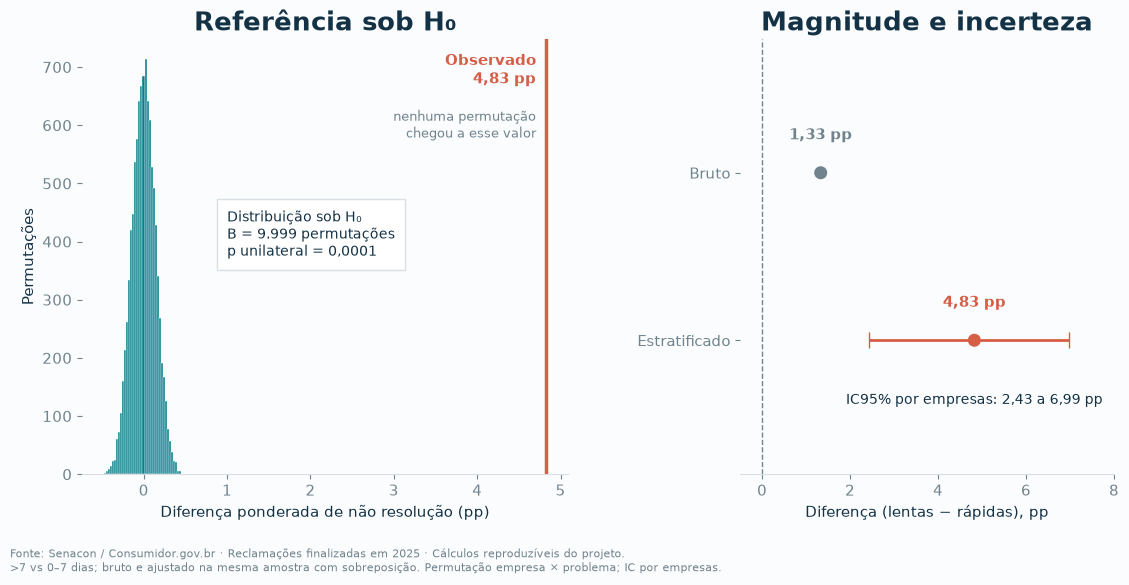

In [12]:
ci, n_companies = stats.cluster_bootstrap(tab, replicates=config.BOOTSTRAP_REPLICATES, seed=config.SEED + 1)
crude_same = (tab['y1'].sum() / tab['n1'].sum() - tab['y0'].sum() / tab['n0'].sum()) * 100
primary = {'effect_pp': observed * 100, 'ci95_cluster_pp': ci, 'p_value': p, 'crude_same_overlap_effect_pp': crude_same}

say(f"Efeito estratificado: {observed * 100:+.2f} pp · IC95% por {n_companies:,} empresas: {ci[0]:.2f} a {ci[1]:.2f} pp")
print('Decisão:', 'rejeitar H₀ ao nível de 5%' if p <= config.ALPHA else 'não rejeitar H₀')
plots.permutacao_e_efeito(null, primary);

**Leitura:** se H₀ fosse verdadeira, T ficaria entre −0,5 e +0,6 pp. O valor observado, +4,83 pp, está muito fora disso, e nenhuma das 9.999 permutações chegou perto. p = 0,0001 é o menor valor reportável com esse B. Ele **não** significa "99,99% de chance de H₁ ser verdadeira". Em termos práticos, a cada 100 reclamações comparáveis, cerca de 5 a mais terminam sem solução quando a resposta passa de 7 dias.

## 6. O resultado depende das escolhas?

O corte de 7 dias e a definição dos estratos foram escolhas. As alternativas abaixo estavam previstas no plano e servem como leitura de robustez, não como novos testes.

In [13]:
sensitivity = pipeline.sensitivity_analyses(analytic)
pd.DataFrame(sensitivity)[['label', 'effect_pp', 'coverage_fraction', 'eligible_strata']] \
  .assign(coverage_fraction=lambda x: x['coverage_fraction'] * 100) \
  .rename(columns={'label': 'especificação', 'effect_pp': 'efeito (pp)', 'coverage_fraction': '% da amostra', 'eligible_strata': 'estratos'}) \
  .style.format({'efeito (pp)': '{:+.2f}', '% da amostra': '{:.1f}%', 'estratos': '{:,.0f}'}, **fmt).hide(axis='index')

especificação,efeito (pp),% da amostra,estratos
>5 dias · empresa × problema,"+4,73","98,9%",4.065
>10 dias · empresa × problema,"+3,58","79,6%",1.709
>7 dias · segmento × problema,"+4,14","100,0%",309


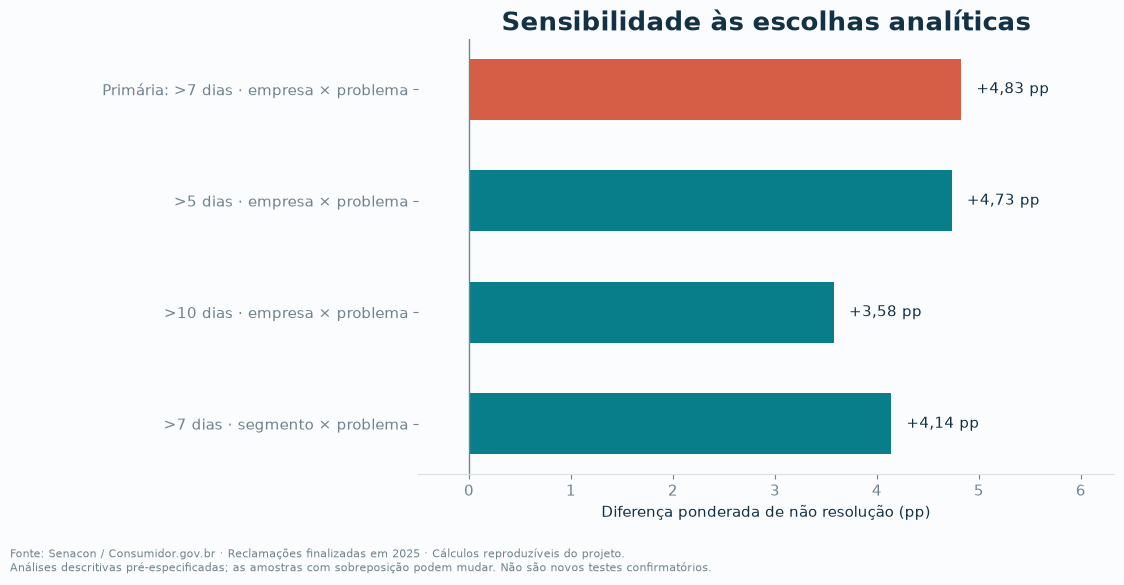

In [14]:
plots.sensibilidade(primary, sensitivity);

## 7. Onde a dor se concentra

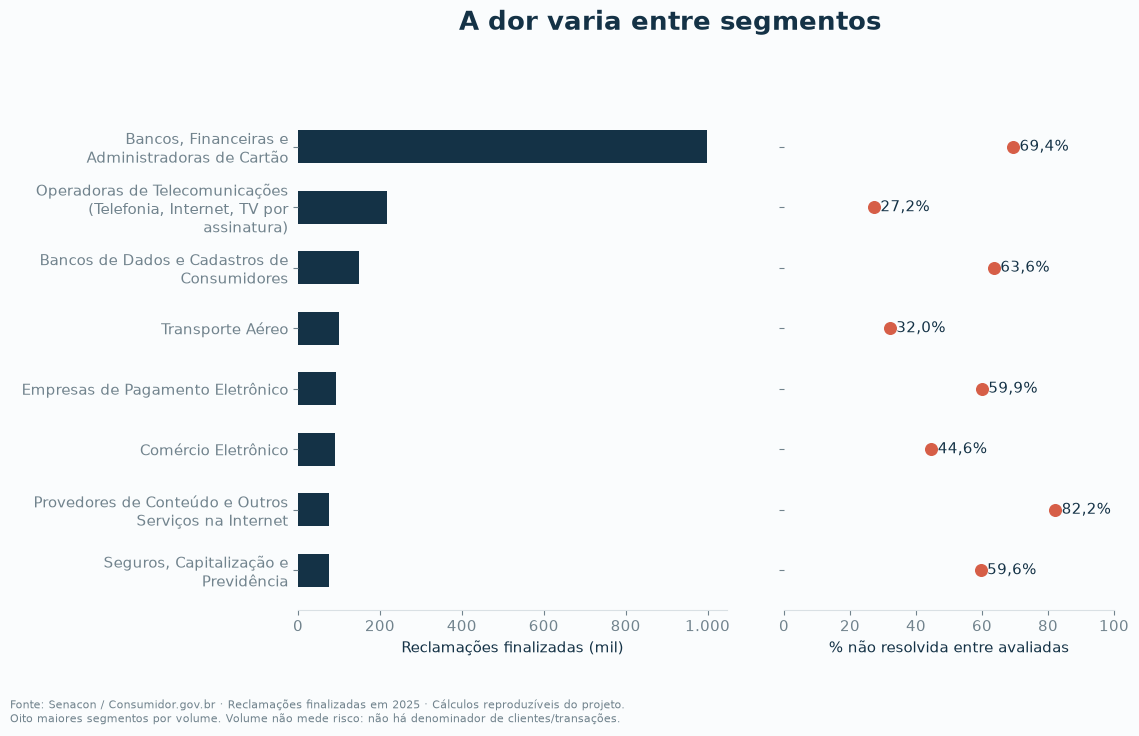

In [15]:
seg = describe.segments(df)
plots.segmentos(seg);

## 8. Conferência com os resultados publicados

Tudo acima foi recalculado neste notebook. A célula abaixo garante que os números batem com `reports/metrics.json`, gerado por `python -m atendimento analisar`.

In [16]:
published = json.loads(config.METRICS.read_text(encoding='utf-8'))['primary']
assert abs(published['effect_pp'] - observed * 100) < 1e-9
assert published['p_value'] == p and published['extreme_count'] == extremes
assert all(abs(a - b) < 1e-9 for a, b in zip(published['ci95_cluster_pp'], ci))
assert published['included_rows'] == coverage['included_rows']
print('OK: efeito, p-valor, IC e cobertura idênticos aos publicados.')

OK: efeito, p-valor, IC e cobertura idênticos aos publicados.


## Conclusão

- **A dor é real e mensurável:** 432 mil reclamações avaliadas como não resolvidas em 2025, 56% das avaliadas.
- **Rejeitamos H₀:** comparando dentro da mesma empresa e problema, respostas acima de 7 dias têm +4,83 pp de não resolução (IC95% de 2,43 a 6,99 pp; p = 0,0001; permutação estratificada). O resultado se mantém com outros cortes e estratos.
- **Responder ≠ resolver:** respostas muito rápidas também falham com frequência. O sistema de chamados precisa acompanhar o prazo **e** a solução confirmada.

**Limites:** o estudo é observacional e mostra associação, não causa. Só 33% das reclamações são avaliadas, e casos mais complexos podem ser, ao mesmo tempo, mais demorados e mais difíceis de resolver. Saber se o sistema *melhora* esses números exige um piloto controlado, descrito no [relatório](../reports/relatorio.md).